## 2.2 Gắn nhãn và cắt cửa sổ
- Đầu vào: `data/clean_1min/*.parquet` (từ data_standardising.ipynb).
- Nhãn: `y = 1` nếu SpO2 (trung bình phút) < 88% liên tục ≥ 3 phút xảy ra trong 30 phút tiếp theo.
- Mỗi cửa sổ gồm 60 phút đầu vào, 4 kênh, và đầu vào **không được chứa sự kiện**.
- Đầu ra: `data/windows_thr88/<record>.npz` (X, y, start) và `data/windows_thr88_summary.parquet`.
- Có resume: record nào đã có file `.npz` thì bỏ qua. Đổi tham số thì dùng thư mục đầu ra mới.
- Chưa chia train/val/test. Việc đó làm ở data_splitting.ipynb, theo bệnh nhân.

In [1]:
import os, glob, numpy as np, pandas as pd
from tqdm.auto import tqdm

CLEAN_DIR, WIN_DIR = "data/clean_1min", "data/windows_thr88"
MANIFEST_PATH = "data/download_manifest.parquet"
THR, MIN_EVENT = 88, 3        # sự kiện: spo2_mean < 88% liên tục >= 3 phút
IN_MIN, HORIZON, STRIDE = 60, 30, 5
MIN_VALID = 0.7               # tỷ lệ phút có SpO2 tối thiểu ở đầu vào và ở 30 phút dự đoán
CH = ["spo2_mean", "spo2_min", "spo2_valid", "pulse_mean"]
os.makedirs(WIN_DIR, exist_ok=True)

def event_mask(spo2):
    """True cho mọi phút thuộc một đoạn spo2<THR dài >= MIN_EVENT phút."""
    low = np.nan_to_num(spo2, nan=100) < THR
    d = np.diff(np.r_[0, low.astype(int), 0])
    ev = np.zeros(len(spo2), bool)
    for s, e in zip(np.where(d == 1)[0], np.where(d == -1)[0]):
        if e - s >= MIN_EVENT: ev[s:e] = True
    return ev

def make_windows(d):
    T, W = len(d), IN_MIN + HORIZON
    if T < W: return None
    spo2 = d["spo2_mean"].to_numpy()
    ev, valid = event_mask(spo2), ~np.isnan(spo2)
    ce, cv = np.r_[0, np.cumsum(ev)], np.r_[0, np.cumsum(valid)]
    s = np.arange(0, T - W + 1, STRIDE); m = s + IN_MIN; e = m + HORIZON
    ev_in, ev_h = ce[m] - ce[s], ce[e] - ce[m]
    v_in, v_h = (cv[m] - cv[s]) / IN_MIN, (cv[e] - cv[m]) / HORIZON
    keep = (ev_in == 0) & (v_in >= MIN_VALID) & (v_h >= MIN_VALID)
    s = s[keep]
    if len(s) == 0: return None
    X = d[CH].to_numpy(np.float32)
    return X[s[:, None] + np.arange(IN_MIN)[None, :]], (ev_h[keep] > 0).astype(np.int8), s.astype(np.int32)

files = sorted(glob.glob(f"{CLEAN_DIR}/*.parquet"))
todo = [f for f in files if not os.path.exists(f"{WIN_DIR}/{os.path.basename(f)[:-8]}.npz")]
print(f"Record đã chuẩn hóa: {len(files)} | đã tạo cửa sổ: {len(files) - len(todo)} | còn: {len(todo)}")

for f in tqdm(todo, desc="Windows"):
    name = os.path.basename(f)[:-8]
    out = make_windows(pd.read_parquet(f))
    if out is None:   # vẫn ghi file rỗng để lần sau không xử lý lại
        out = (np.zeros((0, IN_MIN, len(CH)), np.float32), np.zeros(0, np.int8), np.zeros(0, np.int32))
    np.savez_compressed(f"{WIN_DIR}/{name}.tmp.npz", X=out[0], y=out[1], start=out[2])
    os.replace(f"{WIN_DIR}/{name}.tmp.npz", f"{WIN_DIR}/{name}.npz")   # ghi xong mới đổi tên

Record đã chuẩn hóa: 1426 | đã tạo cửa sổ: 1426 | còn: 0


Windows: 0it [00:00, ?it/s]

In [2]:
m = pd.read_parquet(MANIFEST_PATH).query("status == 'ok'").copy()
m["name"] = m["record"].str.split("/").str[-1]
m["loai_fs"] = np.where(m["fs"] > 0.5, "1 Hz", "1 mau/phut")
m = m[m["name"].isin([os.path.basename(f)[:-4] for f in glob.glob(f"{WIN_DIR}/*.npz")])]
ys = {n: np.load(f"{WIN_DIR}/{n}.npz")["y"] for n in m["name"]}
m["n_win"] = m["name"].map(lambda n: len(ys[n])); m["n_pos"] = m["name"].map(lambda n: int(ys[n].sum()))

print(f"Cửa sổ: {m['n_win'].sum():,} | dương: {m['n_pos'].sum():,} ({m['n_pos'].sum() / m['n_win'].sum():.1%})")
p = m.groupby("patient_id")[["n_win", "n_pos"]].sum()
r = p["n_pos"] / p["n_win"].clip(lower=1)
print(f"Bệnh nhân có cửa sổ: {(p['n_win'] > 0).sum()} | có ít nhất 1 cửa sổ dương: {(p['n_pos'] > 0).sum()}")
print(f"Tỷ lệ dương theo bệnh nhân (trung vị / p90): {r.median():.1%} / {r.quantile(.9):.1%}")
g = m.groupby("loai_fs")[["n_win", "n_pos"]].sum(); g["ty_le_duong"] = (g["n_pos"] / g["n_win"]).round(3)
display(g)
print(f"Dung lượng khi nạp RAM (float32): {m['n_win'].sum() * IN_MIN * len(CH) * 4 / 1e9:.1f} GB")

m[["record", "patient_id", "name", "loai_fs", "n_win", "n_pos"]].to_parquet(f"{WIN_DIR}_summary.parquet", index=False)

Cửa sổ: 482,308 | dương: 5,990 (1.2%)
Bệnh nhân có cửa sổ: 799 | có ít nhất 1 cửa sổ dương: 360
Tỷ lệ dương theo bệnh nhân (trung vị / p90): 0.0% / 4.3%


,n_win,n_pos,ty_le_duong
loai_fs,,,
1 Hz,331665,4074,0.012
1 mau/phut,150643,1916,0.013


Dung lượng khi nạp RAM (float32): 0.5 GB


Số BN chứa 80% cửa sổ dương: 174 / 360


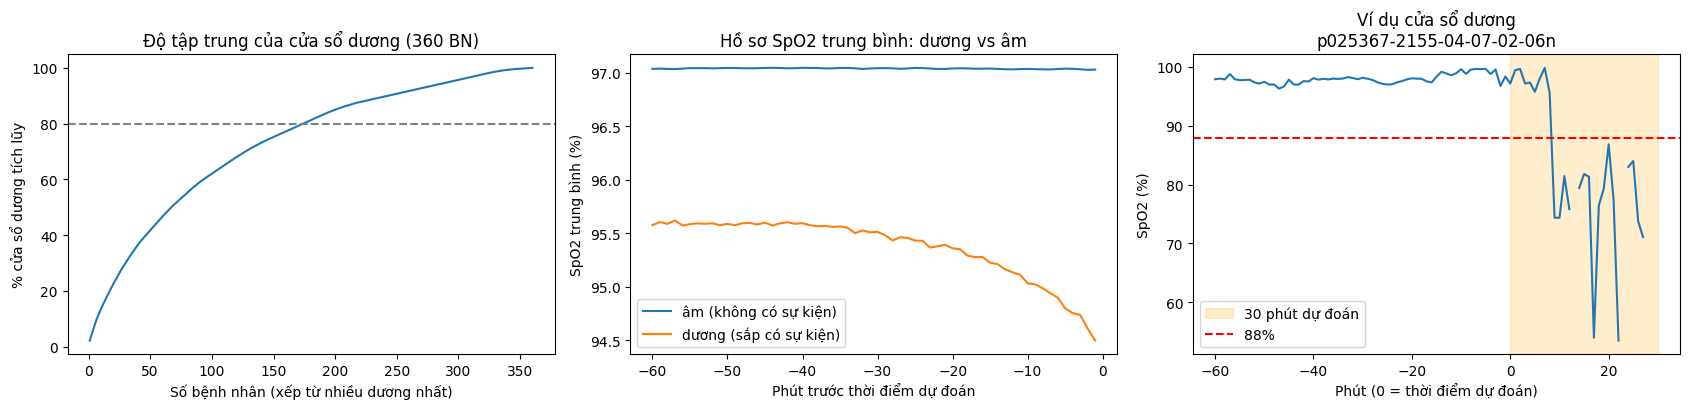

In [3]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))

# (1) Cửa sổ dương tập trung ở bao nhiêu bệnh nhân?
pp = m.groupby("patient_id")["n_pos"].sum().sort_values(ascending=False)
pp = pp[pp > 0]
ax[0].plot(np.arange(1, len(pp) + 1), pp.cumsum() / pp.sum() * 100)
ax[0].axhline(80, ls="--", c="gray"); ax[0].set_xlabel("Số bệnh nhân (xếp từ nhiều dương nhất)")
ax[0].set_ylabel("% cửa sổ dương tích lũy"); ax[0].set_title(f"Độ tập trung của cửa sổ dương ({len(pp)} BN)")
print(f"Số BN chứa 80% cửa sổ dương: {(pp.cumsum() / pp.sum() < 0.8).sum() + 1} / {len(pp)}")

# (2) Hồ sơ SpO2 trung bình trong 60 phút đầu vào: dương vs âm
i_sp = CH.index("spo2_mean")
acc = {k: [np.zeros(IN_MIN), np.zeros(IN_MIN)] for k in (0, 1)}   # [tổng, số điểm hợp lệ]
for n in m.loc[m["n_win"] > 0, "name"]:
    z = np.load(f"{WIN_DIR}/{n}.npz"); X, y = z["X"][:, :, i_sp], z["y"]
    for k in (0, 1):
        Xk = X[y == k]
        if k == 0 and len(Xk) > 200: Xk = Xk[np.random.default_rng(0).choice(len(Xk), 200, replace=False)]
        acc[k][0] += np.nansum(Xk, 0); acc[k][1] += (~np.isnan(Xk)).sum(0)
for k, lab in ((0, "âm (không có sự kiện)"), (1, "dương (sắp có sự kiện)")):
    ax[1].plot(np.arange(-IN_MIN, 0), acc[k][0] / np.maximum(acc[k][1], 1), label=lab)
ax[1].set_xlabel("Phút trước thời điểm dự đoán"); ax[1].set_ylabel("SpO2 trung bình (%)")
ax[1].set_title("Hồ sơ SpO2 trung bình: dương vs âm"); ax[1].legend()

# (3) Một cửa sổ dương mẫu, kèm 30 phút sau để thấy sự kiện (chạy lại cell để xem ví dụ khác)
rng = np.random.default_rng()
n = rng.choice(m.loc[m["n_pos"] > 0, "name"].to_numpy())
z = np.load(f"{WIN_DIR}/{n}.npz"); i = rng.choice(np.where(z["y"] == 1)[0]); s0 = int(z["start"][i])
full = pd.read_parquet(f"{CLEAN_DIR}/{n}.parquet")["spo2_mean"].to_numpy()[s0: s0 + IN_MIN + HORIZON]
ax[2].plot(range(-IN_MIN, HORIZON)[:len(full)], full)
ax[2].axvspan(0, HORIZON, color="orange", alpha=.2, label="30 phút dự đoán"); ax[2].axhline(THR, ls="--", c="r", label=f"{THR}%")
ax[2].set_xlabel("Phút (0 = thời điểm dự đoán)"); ax[2].set_ylabel("SpO2 (%)"); ax[2].set_title(f"Ví dụ cửa sổ dương\n{n}"); ax[2].legend()
plt.tight_layout(); plt.show()